# 12. External errors and class-level adaptation trade-offs

Notebook 11 found higher aggregate external accuracy for both mixed-domain models.
This notebook examines which classes and photographs account for those changes,
using the saved predictions without further inference or model updates.

RQ2 requires class-level interpretation of the aggregate changes. The analysis asks
which classes benefit or deteriorate; why mixed ResNet18 can
improve overall while losing Early Blight recall; how self-collected Healthy and
online disease results differ; and what qualitative patterns appear in selected
errors. Arithmetic explanations are distinguished from hypotheses about visual cues.

## Environment and prediction inputs

Set `PLANT_EXTERNAL_EVAL_RUN` to select a completed evaluation directory, using an
absolute or repository-relative path. Otherwise, the newest complete, verified
four-model run is selected. Each run is checked as a unit before images are paired;
the analysis does not perform inference or require an earlier execution directory.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from zoneinfo import ZoneInfo
from uuid import uuid4
from urllib.parse import quote, urlparse
from html import escape
import hashlib
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.metrics import accuracy_score, f1_score, classification_report
from IPython.display import display, Markdown, HTML

root_override = os.environ.get("PLANT_PROJECT_ROOT")
candidates = [Path(root_override)] if root_override else [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / "data/splits/label_map.json").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open from the repository or set PLANT_PROJECT_ROOT.")
DATA_ROOT = PROJECT_ROOT / "data/external_evaluation/tomato_field_eval_v1"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11})

MODEL_NAMES = {
    "resnet_lab": "ResNet18 · Lab baseline", "vit_lab": "ViT-Small · Lab baseline",
    "resnet_mixed": "ResNet18 · Geometric + Mixed", "vit_mixed": "ViT-Small · Mixed",
}
ARCHITECTURES = {key: "resnet18" if key.startswith("resnet") else "vit_small_patch16_224.augreg_in1k"
                 for key in MODEL_NAMES}
SHORT_NAMES = {"resnet_lab": "CNN Lab", "vit_lab": "ViT Lab",
               "resnet_mixed": "CNN Mixed", "vit_mixed": "ViT Mixed"}
CLASS_NAMES = ["Healthy", "Early Blight", "Late Blight", "Bacterial Spot", "Septoria Leaf Spot"]
LABEL_IDS = list(range(5))
LABEL_MAP = dict(zip(CLASS_NAMES, LABEL_IDS))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

In [2]:
manifest_path = DATA_ROOT / "manifest.csv"
manifest = pd.read_csv(manifest_path, keep_default_na=False)
assert len(manifest) == 62 and manifest.image_id.is_unique
assert json.loads((PROJECT_ROOT / "data/splits/label_map.json").read_text()) == LABEL_MAP
assert (manifest.class_name.map(LABEL_MAP) == manifest.label_id).all()
assert manifest.class_name.value_counts().to_dict() == {
    "Healthy": 16, "Early Blight": 13, "Late Blight": 11,
    "Bacterial Spot": 9, "Septoria Leaf Spot": 13,
}
MANIFEST_SHA256 = sha256_file(manifest_path)
local_checkpoint_names = {
    "resnet_lab": "resnet18_lab_best.pt", "vit_lab": "vit_small_lab_best.pt",
    "resnet_mixed": "resnet18_geometric_mixed_best.pt", "vit_mixed": "vit_small_mixed_best.pt",
}
local_checkpoint_hashes = {key: sha256_file(PROJECT_ROOT / "models" / filename)
                           for key,filename in local_checkpoint_names.items()
                           if (PROJECT_ROOT / "models" / filename).is_file()}
geometric_source = PROJECT_ROOT / "models/resnet18_aug_geometric_best.pt"
geometric_source_hash = sha256_file(geometric_source) if geometric_source.is_file() else None
available_images = set()
for row in manifest.itertuples():
    image_path = (DATA_ROOT / row.image_path).resolve()
    assert image_path.is_relative_to(DATA_ROOT.resolve()), row.image_path
    if image_path.is_file():
        assert sha256_file(image_path) == row.sha256, row.image_id
        available_images.add(row.image_id)

def require(condition, message):
    if not condition:
        raise ValueError(message)

def valid_digest(value):
    return isinstance(value, str) and re.fullmatch(r"[0-9a-f]{64}", value) is not None

In [3]:
def validate_provenance(record):
    require(record.get("complete_four_model_evaluation") is True, "Four-model evaluation is incomplete.")
    require(record.get("training_or_tuning_performed") is False, "Run does not declare inference-only evaluation.")
    require(record.get("manifest_sha256") == MANIFEST_SHA256, "Dataset manifest checksum differs.")
    require(record.get("dataset_id", "tomato_field_eval_v1") == "tomato_field_eval_v1", "Dataset identity differs.")
    require(record.get("class_mapping") == LABEL_MAP, "Class mapping differs.")
    require(record.get("macro_f1_labels") == LABEL_IDS, "Metric label order differs.")
    require(record.get("image_sha256") == dict(zip(manifest.image_id, manifest.sha256)), "Image identities differ.")
    require(isinstance(record.get("run_id"), str) and bool(record["run_id"]), "Missing run ID.")
    completed = datetime.fromisoformat(record["completed_at_utc"])
    require(completed.tzinfo is not None, "Completion time must include its time zone.")
    statuses = pd.DataFrame(record["model_status"]).set_index("model_key")
    require(statuses.index.is_unique and set(statuses.index) == set(MODEL_NAMES), "Model status roster differs.")
    require(statuses.status.eq("evaluated").all() and statuses.images.eq(62).all(), "Some models are incomplete.")
    hashes = record.get("prediction_files_sha256", {})
    require(set(hashes) == set(MODEL_NAMES) and all(map(valid_digest, hashes.values())),
            "Missing prediction checksums; use a self-contained Notebook 11 export.")
    entries = record["checkpoints_and_preprocessing"]
    require(set(entries) == set(MODEL_NAMES), "Checkpoint roster differs.")
    for key, entry in entries.items():
        require(entry["architecture"] == ARCHITECTURES[key], f"Architecture mismatch: {key}.")
        require(all(valid_digest(entry.get(field)) for field in ("checkpoint_sha256", "source_checkpoint_sha256")),
                f"Invalid checkpoint checksums: {key}.")
        if key in local_checkpoint_hashes:
            require(entry["checkpoint_sha256"] == local_checkpoint_hashes[key], f"Local checkpoint identity differs: {key}.")
        state = entry["checkpoint_metadata"]
        require(state["architecture"] == ARCHITECTURES[key] and state["class_names"] == CLASS_NAMES,
                f"Checkpoint labels or architecture differ: {key}.")
        phase = "mixed_domain" if key.endswith("mixed") else "lab_only"
        require(entry["phase"] == phase, f"Checkpoint phase mismatch: {key}.")
        if phase == "mixed_domain":
            experiment = "R2_resnet_geometric" if key.startswith("resnet") else "V1_vit_small"
            require(state["adaptation_type"] == "balanced_mixed_domain" and state["experiment"] == experiment,
                    f"Mixed experiment mismatch: {key}.")
            require(state["source_checkpoint_sha256"] == entry["source_checkpoint_sha256"], f"Source lineage differs: {key}.")
            for split in ("field_dev", "lab_val"):
                saved_hash = record["historical_split_sha256"][split]
                require(valid_digest(saved_hash) and state["manifest_sha256"][split] == saved_hash,
                        f"Selection manifest mismatch: {key}, {split}.")
                local_split = PROJECT_ROOT / f"data/splits/{split}.csv"
                if local_split.is_file():
                    require(sha256_file(local_split) == saved_hash, f"Local split differs: {split}.")
            require(state["field_dev_sha256"] == record["historical_split_sha256"]["field_dev"], "Field Dev lineage differs.")
        else:
            require(entry["source_checkpoint_sha256"] == entry["checkpoint_sha256"], f"Baseline source mismatch: {key}.")
            require(state["pretrained_weights"] == ("IMAGENET1K_V1" if key.startswith("resnet") else "augreg_in1k"),
                    f"Pretraining identity differs: {key}.")
    vit_config = entries["vit_lab"]["checkpoint_metadata"]["preprocessing_config"]
    require(vit_config == entries["vit_lab"]["preprocessing_config"] == entries["vit_mixed"]["preprocessing_config"],
            "ViT inference configurations differ.")
    require(entries["vit_mixed"]["source_checkpoint_sha256"] == entries["vit_lab"]["checkpoint_sha256"],
            "Mixed ViT source is not this laboratory checkpoint.")
    if geometric_source_hash is not None:
        require(entries["resnet_mixed"]["source_checkpoint_sha256"] == geometric_source_hash,
                "Local geometric source identity differs.")
    require(vit_config["input_size"] == [3, 224, 224] and vit_config["interpolation"] == "bicubic"
            and vit_config["mean"] == [0.5]*3 and vit_config["std"] == [0.5]*3
            and vit_config["crop_pct"] == 0.9 and vit_config["crop_mode"] == "center", "ViT preprocessing differs.")
    for key in ("resnet_lab", "resnet_mixed"):
        require(entries[key]["preprocessing_config"] == {
            "source": "torchvision.ResNet18_Weights.IMAGENET1K_V1.transforms"
        }, f"ResNet18 preprocessing differs: {key}.")
    return completed

In [4]:
def validate_prediction_file(run, key, record, saved_summary):
    path = run / f"predictions_{key}.csv"
    digest = sha256_file(path)
    require(digest == record["prediction_files_sha256"][key], f"Prediction checksum mismatch: {key}.")
    frame = pd.read_csv(path, keep_default_na=False)
    require(len(frame) == 62 and frame.image_id.is_unique and set(frame.image_id) == set(manifest.image_id),
            f"Image roster differs: {key}.")
    frame = frame.set_index("image_id").loc[manifest.image_id].reset_index()
    for column in manifest.columns:
        require(frame[column].astype(str).tolist() == manifest[column].astype(str).tolist(), f"Metadata differs: {key}, {column}.")
    require(frame.model_key.eq(key).all() and frame.model.eq(MODEL_NAMES[key]).all(), f"Model identity differs: {key}.")
    require(frame.ground_truth_label.eq(frame.class_name).all() and frame.predicted_label_id.isin(LABEL_IDS).all(),
            f"Invalid labels: {key}.")
    require(frame.predicted_label.eq(frame.predicted_label_id.map(dict(enumerate(CLASS_NAMES)))).all(),
            f"Prediction labels differ from IDs: {key}.")
    correct = frame.correct.astype(str).str.lower().map({"true": True, "false": False})
    require(correct.notna().all() and np.array_equal(correct, frame.label_id.eq(frame.predicted_label_id)),
            f"Correctness flags differ: {key}.")
    frame["correct"] = correct.astype(bool)
    probabilities = frame[[f"probability_label_{i}" for i in LABEL_IDS]].to_numpy(dtype=float)
    require(np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
            and np.allclose(probabilities.sum(1), 1, atol=1e-6, rtol=0), f"Invalid probabilities: {key}.")
    require(np.array_equal(probabilities.argmax(1), frame.predicted_label_id)
            and np.allclose(probabilities.max(1), frame.confidence, atol=1e-7, rtol=0),
            f"Argmax or confidence differs: {key}.")
    scores = {"images": len(frame), "correct": int(frame.correct.sum()),
              "accuracy": accuracy_score(frame.label_id, frame.predicted_label_id)}
    for name, average in (("macro_f1", "macro"), ("weighted_f1", "weighted")):
        scores[name] = f1_score(frame.label_id, frame.predicted_label_id, labels=LABEL_IDS, average=average, zero_division=0)
    require(all(np.isclose(value, saved_summary.loc[key, metric], atol=1e-8, rtol=0) for metric,value in scores.items()),
            f"Summary does not reproduce predictions: {key}.")
    return frame, {"model_key": key, "model": MODEL_NAMES[key], **scores}, digest

In [5]:
def validate_run(run):
    run = Path(run).resolve()
    record_path = run / "evaluation_protocol.json"
    record_hash = sha256_file(record_path)
    record = json.loads(record_path.read_text())
    completed = validate_provenance(record)
    summary_path = run / "model_summary.csv"
    summary_hash = sha256_file(summary_path)
    if record.get("summary_sha256") is not None:
        require(summary_hash == record["summary_sha256"], "Model summary checksum differs.")
    saved_summary = pd.read_csv(summary_path).set_index("model_key")
    require(saved_summary.index.is_unique and set(saved_summary.index) == set(MODEL_NAMES), "Summary model roster differs.")
    require(saved_summary.status.eq("evaluated").all() and saved_summary.images.eq(62).all(), "Summary is incomplete.")
    frames, rows, hashes = {}, [], {}
    for key, name in MODEL_NAMES.items():
        require(saved_summary.loc[key, "model"] == name, f"Summary identity differs: {key}.")
        require(saved_summary.loc[key, "phase"] == record["checkpoints_and_preprocessing"][key]["phase"],
                f"Summary phase differs: {key}.")
        frame, scores, digest = validate_prediction_file(run, key, record, saved_summary)
        frames[key] = frame
        rows.append(scores)
        hashes[f"predictions_{key}.csv"] = digest
    require(sha256_file(record_path) == record_hash and sha256_file(summary_path) == summary_hash,
            "Run changed while it was being validated.")
    return {"path": run, "protocol": record, "frames": frames, "scores": rows,
            "hashes": hashes, "completed": completed, "protocol_sha256": record_hash, "summary_sha256": summary_hash}

def select_evaluation_run(explicit_path=None, base=None):
    base = base if base is not None else PROJECT_ROOT / "outputs/external_evaluation/tomato_field_eval_v1"
    if explicit_path is not None:
        require(bool(str(explicit_path).strip()), "PLANT_EXTERNAL_EVAL_RUN must name an evaluation directory.")
        run = Path(explicit_path).expanduser()
        if not run.is_absolute():
            run = PROJECT_ROOT / run
        try:
            return validate_run(run), []
        except (ValueError, KeyError, TypeError, AttributeError, OSError) as error:
            raise ValueError(f"Invalid explicitly selected evaluation run {run}: {error}") from error
    candidates, skipped = [], []
    for run in base.iterdir() if base.is_dir() else []:
        if not run.is_dir():
            continue
        try:
            record = json.loads((run / "evaluation_protocol.json").read_text())
            completed = datetime.fromisoformat(record["completed_at_utc"])
            require(completed.tzinfo is not None, "Completion time lacks a time zone.")
            candidates.append((completed, run))
        except (ValueError, KeyError, TypeError, OSError) as error:
            skipped.append(f"{run.name}: {error}")
    for _, run in sorted(candidates, key=lambda item: (item[0], item[1].name), reverse=True):
        try:
            return validate_run(run), skipped
        except (ValueError, KeyError, TypeError, AttributeError, OSError) as error:
            skipped.append(f"{run.name}: {error}")
    raise ValueError("No valid complete four-model evaluation run was found. "
                     "Run Notebook 11 or provide PLANT_EXTERNAL_EVAL_RUN.\n" + "\n".join(skipped))

In [6]:
selected_run, skipped_runs = select_evaluation_run(os.environ.get("PLANT_EXTERNAL_EVAL_RUN"))
EVALUATION_RUN, protocol = selected_run["path"], selected_run["protocol"]
frames, reproduced_rows, input_hashes = selected_run["frames"], selected_run["scores"], selected_run["hashes"]
protocol_path = EVALUATION_RUN / "evaluation_protocol.json"
RUN_ID = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
OUTPUT_ROOT = PROJECT_ROOT / "outputs/external_error_analysis/tomato_field_eval_v1" / RUN_ID
OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)
(OUTPUT_ROOT / "input_validation.log").write_text(
    f"Selected run: {protocol['run_id']}\nVerified four models on 62 images each.\n"
    f"Available source photographs: {len(available_images)}/62.\n" + "\n".join(skipped_runs), encoding="utf-8"
)
print("Selected evaluation run:", protocol["run_id"])

Selected evaluation run: 20261125_163347_4ca8183f


In [7]:
class_rows = []
for key, frame in frames.items():
    report = classification_report(frame.label_id, frame.predicted_label_id, labels=LABEL_IDS,
                                   target_names=CLASS_NAMES, zero_division=0, output_dict=True)
    for label, class_name in enumerate(CLASS_NAMES):
        class_rows.append({"model_key": key, "model": MODEL_NAMES[key], "class_name": class_name,
                           "images": int(report[class_name]["support"]),
                           "correct": int((frame.label_id.eq(label) & frame.correct).sum()),
                           "precision": report[class_name]["precision"], "recall": report[class_name]["recall"],
                           "f1": report[class_name]["f1-score"]})
class_metrics = pd.DataFrame(class_rows)
class_metrics.to_csv(OUTPUT_ROOT / "class_model_metrics.csv", index=False)
paired = manifest.copy()
for key, frame in frames.items():
    for field in ("predicted_label", "predicted_label_id", "confidence", "correct"):
        paired[f"{key}_{field}"] = frame[field].to_numpy()
paired["source_host"] = paired.source_url.map(lambda value: urlparse(value).hostname or "self-collected")
display(pd.DataFrame(reproduced_rows)[["model", "correct", "images", "accuracy", "macro_f1"]].round(4))

,model,correct,images,accuracy,macro_f1
0,ResNet18 · Lab baseline,19,62,0.3065,0.2406
1,ViT-Small · Lab baseline,27,62,0.4355,0.4157
2,ResNet18 · Geometric + Mixed,33,62,0.5323,0.4882
3,ViT-Small · Mixed,32,62,0.5161,0.4808


## Class-level performance changes

Baseline and mixed predictions are paired on the same images. A recovered prediction
is wrong at baseline and correct after adaptation; a lost prediction changes in the
opposite direction. Net changes reconcile to the difference in total correct counts.
Precision, recall and F1 are computed for all five classes with undefined values set
to zero. Small differences are descriptive rather than statistically conclusive.

In [8]:
class_order = pd.Categorical(class_metrics.class_name, categories=CLASS_NAMES, ordered=True)
ordered_class_metrics = class_metrics.assign(class_order=class_order).sort_values("class_order", kind="stable")
display(ordered_class_metrics.set_index(["class_name", "model"])[["images", "correct", "precision", "recall", "f1"]].round(3))
changes = []
for architecture in ("resnet", "vit"):
    baseline, mixed = f"{architecture}_lab", f"{architecture}_mixed"
    for name in CLASS_NAMES:
        group = paired.loc[paired.class_name.eq(name)]
        base_score = class_metrics.loc[class_metrics.model_key.eq(baseline) & class_metrics.class_name.eq(name)].iloc[0]
        mixed_score = class_metrics.loc[class_metrics.model_key.eq(mixed) & class_metrics.class_name.eq(name)].iloc[0]
        row = {"architecture": architecture, "class_name": name, "images": len(group),
               "baseline_correct": int(group[f"{baseline}_correct"].sum()),
               "mixed_correct": int(group[f"{mixed}_correct"].sum()),
               "recovered": int((~group[f"{baseline}_correct"] & group[f"{mixed}_correct"]).sum()),
               "lost": int((group[f"{baseline}_correct"] & ~group[f"{mixed}_correct"]).sum())}
        row["net_correct"] = row["recovered"] - row["lost"]
        assert row["net_correct"] == row["mixed_correct"] - row["baseline_correct"]
        for metric in ("precision", "recall", "f1"):
            row[f"baseline_{metric}"] = base_score[metric]
            row[f"mixed_{metric}"] = mixed_score[metric]
            row[f"delta_{metric}"] = mixed_score[metric] - base_score[metric]
        changes.append(row)
changes = pd.DataFrame(changes)
changes.to_csv(OUTPUT_ROOT / "class_adaptation_changes.csv", index=False)
display(changes[["architecture", "class_name", "images", "baseline_correct", "mixed_correct", "recovered", "lost",
                 "delta_precision", "delta_recall", "delta_f1"]].round(3))

images  correct  precision  \
class_name         model                                                      
Healthy            ResNet18 · Lab baseline           16        0      0.000   
                   ViT-Small · Lab baseline          16        5      1.000   
                   ResNet18 · Geometric + Mixed      16       12      0.800   
                   ViT-Small · Mixed                 16       13      0.929   
Early Blight       ResNet18 · Lab baseline           13       11      0.282   
                   ViT-Small · Lab baseline          13        3      0.375   
                   ResNet18 · Geometric + Mixed      13        1      0.500   
                   ViT-Small · Mixed                 13        2      0.400   
Late Blight        ResNet18 · Lab baseline           11        5      0.278   
                   ViT-Small · Lab baseline          11        8      0.421   
                   ResNet18 · Geometric + Mixed      11        8      0.421   
                   ViT-Small · Mixed                 11        8      0.444   
Bacterial Spot     ResNet18 · Lab baseline            9        1      1.000   
                   ViT-Small · Lab baseline           9        2      0.667   
                   ResNet18 · Geometric + Mixed       9        5      0.333   
                   ViT-Small · Mixed                  9        5      0.312   
Septoria Leaf Spot ResNet18 · Lab baseline           13        2      0.500   
                   ViT-Small · Lab baseline          13        9      0.333   
                   ResNet18 · Geometric + Mixed      13        7      0.636   
                   ViT-Small · Mixed                 13        4      0.444   

                                                 recall     f1  
class_name         model                                        
Healthy            ResNet18 · Lab baseline        0.000  0.000  
                   ViT-Small · Lab baseline       0.312  0.476  
                   ResNet18 · Geometric + Mixed   0.750  0.774  
                   ViT-Small · Mixed              0.812  0.867  
Early Blight       ResNet18 · Lab baseline        0.846  0.423  
                   ViT-Small · Lab baseline       0.231  0.286  
                   ResNet18 · Geometric + Mixed   0.077  0.133  
                   ViT-Small · Mixed              0.154  0.222  
Late Blight        ResNet18 · Lab baseline        0.455  0.345  
                   ViT-Small · Lab baseline       0.727  0.533  
                   ResNet18 · Geometric + Mixed   0.727  0.533  
                   ViT-Small · Mixed              0.727  0.552  
Bacterial Spot     ResNet18 · Lab baseline        0.111  0.200  
                   ViT-Small · Lab baseline       0.222  0.333  
                   ResNet18 · Geometric + Mixed   0.556  0.417  
                   ViT-Small · Mixed              0.556  0.400  
Septoria Leaf Spot ResNet18 · Lab baseline        0.154  0.235  
                   ViT-Small · Lab baseline       0.692  0.450  
                   ResNet18 · Geometric + Mixed   0.538  0.583  
                   ViT-Small · Mixed              0.308  0.364

,architecture,class_name,images,baseline_correct,mixed_correct,recovered,lost,delta_precision,delta_recall,delta_f1
0,resnet,Healthy,16,0,12,12,0,0.800,0.750,0.774
1,resnet,Early Blight,13,11,1,0,10,0.218,-0.769,-0.290
2,resnet,Late Blight,11,5,8,3,0,0.143,0.273,0.189
3,resnet,Bacterial Spot,9,1,5,4,0,-0.667,0.444,0.217
4,resnet,Septoria Leaf Spot,13,2,7,5,0,0.136,0.385,0.348
5,vit,Healthy,16,5,13,8,0,-0.071,0.500,0.390
6,vit,Early Blight,13,3,2,0,1,0.025,-0.077,-0.063
7,vit,Late Blight,11,8,8,2,2,0.023,0.000,0.018
8,vit,Bacterial Spot,9,2,5,3,0,-0.354,0.333,0.067
9,vit,Septoria Leaf Spot,13,9,4,0,5,0.111,-0.385,-0.086


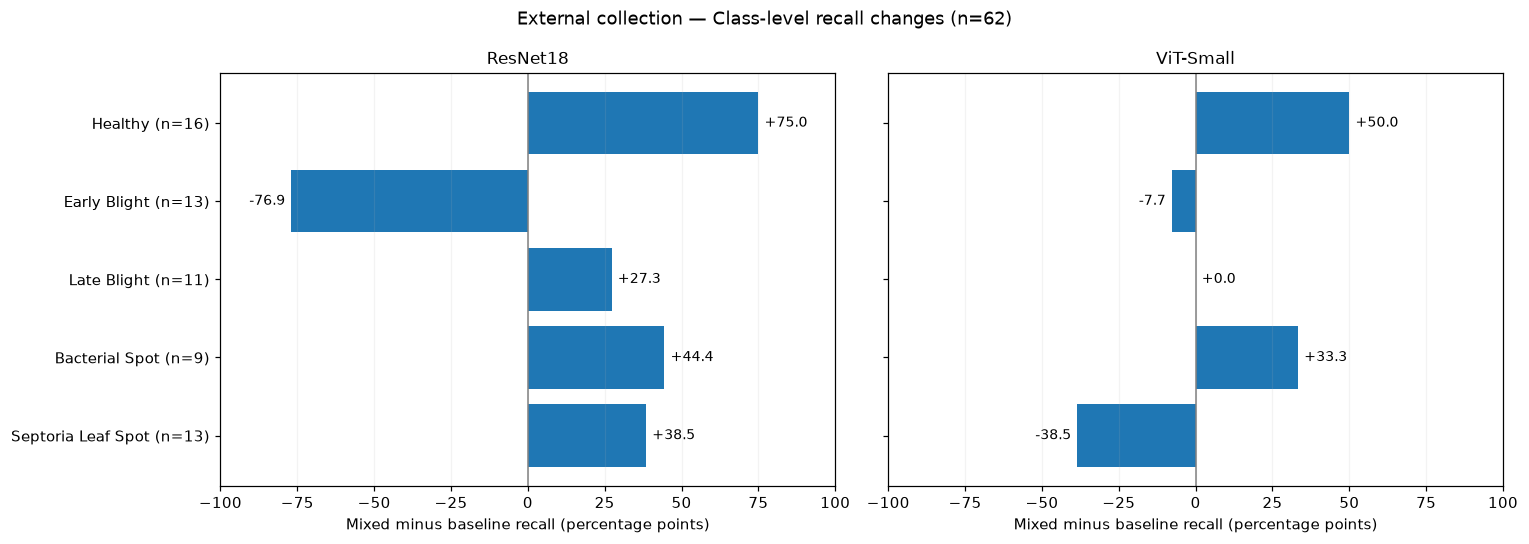

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, architecture, title in zip(axes, ("resnet", "vit"), ("ResNet18", "ViT-Small")):
    selected = changes.loc[changes.architecture.eq(architecture)].set_index("class_name").loc[CLASS_NAMES]
    bars = ax.barh(np.arange(5), 100 * selected.delta_recall, color="#1f77b4")
    for bar, row in zip(bars, selected.itertuples()):
        value = 100 * row.delta_recall
        ax.text(value + (2 if value >= 0 else -2), bar.get_y() + bar.get_height()/2,
                f"{value:+.1f}", va="center", ha="left" if value >= 0 else "right", fontsize=9)
    ax.axvline(0, color="gray", linewidth=1)
    ax.set(yticks=np.arange(5), yticklabels=[f"{name} (n={int(selected.loc[name, 'images'])})" for name in CLASS_NAMES],
           xlim=(-100, 100), xlabel="Mixed minus baseline recall (percentage points)", title=title)
    ax.grid(axis="x", alpha=0.15)
axes[0].invert_yaxis()
fig.suptitle("External collection — Class-level recall changes (n=62)")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "class_recall_changes.png", dpi=160)
plt.show()
plt.close(fig)

In [10]:
notes = []
for architecture, title in (("resnet", "ResNet18"), ("vit", "ViT-Small")):
    c = changes.loc[changes.architecture.eq(architecture)]
    gains = ", ".join(f"{r.class_name} (+{r.net_correct})" for r in c.itertuples() if r.net_correct > 0)
    losses = ", ".join(f"{r.class_name} ({r.net_correct})" for r in c.itertuples() if r.net_correct < 0)
    notes.append(f"**{title}:** net gains in {gains}; losses in {losses}. "
                 f"Recovered {int(c.recovered.sum())} and lost {int(c.lost.sum())} predictions, "
                 f"for a net change of {int(c.net_correct.sum()):+d}/62.")
display(Markdown("\n\n".join(notes)))

**ResNet18:** net gains in Healthy (+12), Late Blight (+3), Bacterial Spot (+4), Septoria Leaf Spot (+5); losses in Early Blight (-10). Recovered 24 and lost 10 predictions, for a net change of +14/62.

**ViT-Small:** net gains in Healthy (+8), Bacterial Spot (+3); losses in Early Blight (-1), Septoria Leaf Spot (-5). Recovered 13 and lost 8 predictions, for a net change of +5/62.

## Early Blight errors

This class contains 13 online images. The analysis compares the complete image-level predictions,
then examines the mixed models' destinations and changes across source pages and image
types. An apparent concentration on a source page does not establish a source effect:
the photographs differ and may share scene or acquisition characteristics.

In [11]:
prediction_columns = [f"{key}_predicted_label" for key in MODEL_NAMES]
confidence_columns = [f"{key}_confidence" for key in MODEL_NAMES]
early = paired.loc[paired.class_name.eq("Early Blight")].copy()
for architecture in ("resnet", "vit"):
    early[f"{architecture}_lost"] = early[f"{architecture}_lab_correct"] & ~early[f"{architecture}_mixed_correct"]
early.to_csv(OUTPUT_ROOT / "early_blight_comparison.csv", index=False)
display(early[["filename", "class_name", "image_type", *prediction_columns]].rename(
    columns={f"{key}_predicted_label": label for key, label in SHORT_NAMES.items()}
))
destinations = pd.DataFrame({SHORT_NAMES[key]: early[f"{key}_predicted_label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
                             for key in MODEL_NAMES})
destinations.index.name = "predicted_class"
destinations.to_csv(OUTPUT_ROOT / "early_blight_destinations.csv")
display(destinations)

,filename,class_name,image_type,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
23,WEB_0008.png,Early Blight,multi_leaf,Early Blight,Septoria Leaf Spot,Bacterial Spot,Septoria Leaf Spot
24,WEB_0009.png,Early Blight,multi_leaf,Early Blight,Late Blight,Bacterial Spot,Late Blight
25,WEB_0010.jpg,Early Blight,single_leaf,Early Blight,Early Blight,Bacterial Spot,Early Blight
26,WEB_0011.jpg,Early Blight,multi_leaf,Early Blight,Septoria Leaf Spot,Septoria Leaf Spot,Bacterial Spot
27,WEB_0012.jpg,Early Blight,multi_leaf,Late Blight,Late Blight,Late Blight,Late Blight
28,WEB_0013.jpg,Early Blight,multi_leaf,Early Blight,Septoria Leaf Spot,Late Blight,Late Blight
29,WEB_0014.jpg,Early Blight,multi_leaf,Early Blight,Septoria Leaf Spot,Early Blight,Late Blight
30,WEB_0015.jpg,Early Blight,multi_leaf,Early Blight,Late Blight,Late Blight,Late Blight
31,WEB_0016.jpg,Early Blight,multi_leaf,Septoria Leaf Spot,Septoria Leaf Spot,Bacterial Spot,Bacterial Spot
32,WEB_0017.jpg,Early Blight,multi_leaf,Early Blight,Early Blight,Bacterial Spot,Late Blight


,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
predicted_class,,,,
Healthy,0,0,0,0
Early Blight,11,3,1,2
Late Blight,1,5,4,8
Bacterial Spot,0,0,6,2
Septoria Leaf Spot,1,5,2,1


In [12]:
def grouped_correct(frame, fields):
    rows = []
    for values, group in frame.groupby(fields, dropna=False, sort=True):
        values = values if isinstance(values, tuple) else (values,)
        row = {field: value for field, value in zip(fields, values)}
        row["images"] = len(group)
        row["image_ids"] = " | ".join(group.image_id)
        for key in MODEL_NAMES:
            row[f"{key}_correct"] = int(group[f"{key}_correct"].sum())
        rows.append(row)
    return pd.DataFrame(rows)

early_groups = []
for fields in (["image_type"], ["source_host", "source_group_id"]):
    table = grouped_correct(early, fields)
    early_groups.append(table.assign(grouping=" × ".join(fields)))
    shown = table.drop(columns=["image_ids", "source_group_id"], errors="ignore").copy()
    for key in MODEL_NAMES:
        shown[SHORT_NAMES[key]] = shown[f"{key}_correct"].astype(str) + "/" + shown.images.astype(str)
    display(shown.drop(columns=[f"{key}_correct" for key in MODEL_NAMES]))
pd.concat(early_groups, ignore_index=True).to_csv(OUTPUT_ROOT / "early_blight_subgroups.csv", index=False)

lost_early = early.loc[early.resnet_lost]
mixed_dest = early.loc[~early.resnet_mixed_correct, "resnet_mixed_predicted_label"].value_counts()
vit_dest = early.loc[~early.vit_mixed_correct, "vit_mixed_predicted_label"].value_counts()
resnet_change = changes.loc[changes.architecture.eq("resnet")].set_index("class_name")
baseline_early_predictions = int(paired.resnet_lab_predicted_label.eq("Early Blight").sum())
mixed_early_predictions = int(paired.resnet_mixed_predicted_label.eq("Early Blight").sum())
display(Markdown(
    f"ResNet18 Early Blight correct counts fall from {int(early.resnet_lab_correct.sum())}/13 to "
    f"{int(early.resnet_mixed_correct.sum())}/13. The {len(lost_early)} lost predictions span "
    f"{lost_early.source_group_id.nunique()} source pages and "
    f"{', '.join(f'{k} (n={v})' for k,v in lost_early.image_type.value_counts().items())}. "
    f"Mixed CNN errors are assigned to {', '.join(f'{k} ({v})' for k,v in mixed_dest.items())}; "
    f"mixed ViT errors go to {', '.join(f'{k} ({v})' for k,v in vit_dest.items())}.\n\n"
    f"Higher overall CNN accuracy is reconciled by {int(resnet_change.loc['Healthy', 'net_correct']):+d} "
    f"Healthy and {int(resnet_change.drop(index=['Healthy', 'Early Blight']).net_correct.sum()):+d} "
    f"other-disease correct predictions, offsetting {abs(int(resnet_change.loc['Early Blight', 'net_correct']))} "
    "lost Early Blight predictions. This explains the aggregate arithmetic; it does not identify a biological "
    "or learned-feature mechanism. Across the full collection, the CNN predicts Early Blight "
    f"{baseline_early_predictions} times before adaptation and {mixed_early_predictions} times afterward. "
    f"Its Early Blight precision changes from {int(early.resnet_lab_correct.sum())}/{baseline_early_predictions} "
    f"to {int(early.resnet_mixed_correct.sum())}/{mixed_early_predictions}. "
    "The baseline's high recall therefore also comes with many false positives."
))

,image_type,images,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
0,cropped,1,1/1,0/1,0/1,0/1
1,multi_leaf,11,9/11,2/11,1/11,1/11
2,single_leaf,1,1/1,1/1,0/1,1/1


,source_host,images,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
0,ag.purdue.edu,7,5/7,1/7,1/7,0/7
1,blogs.cornell.edu,1,1/1,1/1,0/1,1/1
2,extension.psu.edu,1,1/1,0/1,0/1,0/1
3,hgic.clemson.edu,1,1/1,1/1,0/1,1/1
4,ipm.cahnr.uconn.edu,2,2/2,0/2,0/2,0/2
5,yardandgarden.extension.iastate.edu,1,1/1,0/1,0/1,0/1


ResNet18 Early Blight correct counts fall from 11/13 to 1/13. The 10 lost predictions span 6 source pages and multi_leaf (n=8), single_leaf (n=1), cropped (n=1). Mixed CNN errors are assigned to Bacterial Spot (6), Late Blight (4), Septoria Leaf Spot (2); mixed ViT errors go to Late Blight (8), Bacterial Spot (2), Septoria Leaf Spot (1).

Higher overall CNN accuracy is reconciled by +12 Healthy and +12 other-disease correct predictions, offsetting 10 lost Early Blight predictions. This explains the aggregate arithmetic; it does not identify a biological or learned-feature mechanism. Across the full collection, the CNN predicts Early Blight 39 times before adaptation and 2 times afterward. Its Early Blight precision changes from 11/39 to 1/2. The baseline's high recall therefore also comes with many false positives.

### Representative Early Blight photographs

These selected cases cover a lost multi-leaf prediction, an intact close-up, a crop
and a shared failure. Each sample table retains its filename, true class and four
predictions with softmax confidence. Photographs are linked from local gallery files
and remain outside the saved notebook; the tables and observations survive relocation.

In [13]:
selected_cases = []
def show_gallery(image_ids, reasons, filename, title):
    selected = paired.set_index("image_id").loc[image_ids].reset_index().copy()
    assert selected.image_id.is_unique and len(selected) == len(reasons)
    selected["selection_reason"] = reasons
    selected["gallery"] = filename
    selected_cases.append(selected)
    sample_table = selected[["filename", "class_name", "image_type"]].rename(
        columns={"filename": "Filename", "class_name": "Ground truth", "image_type": "Image type"}
    )
    for key, label in SHORT_NAMES.items():
        sample_table[label] = selected[f"{key}_predicted_label"] + selected[f"{key}_confidence"].map(lambda p: f" ({p:.2f})")
    display(sample_table.reset_index(drop=True))
    if not selected.image_id.isin(available_images).any():
        display(Markdown("Source photographs are unavailable locally; the sample predictions above remain available."))
        return
    fig, axes = plt.subplots(2, 2, figsize=(13, 12), squeeze=False)
    for ax, row, reason in zip(axes.flat, selected.itertuples(), reasons):
        if row.image_id in available_images:
            with Image.open(DATA_ROOT / row.image_path) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                image.thumbnail((900, 900))
                ax.imshow(image)
        else:
            ax.text(0.5, 0.5, "Photograph unavailable", ha="center", va="center")
        lines = [f"{row.filename} | True: {row.class_name}",
                 f"{reason} | {row.image_type}"]
        for key in MODEL_NAMES:
            lines.append(f"{SHORT_NAMES[key]}: {getattr(row, key + '_predicted_label')} "
                         f"({getattr(row, key + '_confidence'):.2f})")
        ax.set_title("\n".join(lines), fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=12)
    fig.subplots_adjust(top=0.85, bottom=0.035, hspace=0.5, wspace=0.1)
    path = OUTPUT_ROOT / filename
    fig.savefig(path, dpi=140)
    plt.close(fig)
    url = quote(os.path.relpath(path, PROJECT_ROOT / "notebooks"), safe="/")
    display(HTML(f'<p><a href="{escape(url)}">Open {escape(title)}</a></p>'
                 '<p>Local gallery; sample predictions remain above if the image file is unavailable.</p>'
                 f'<img src="{escape(url)}" alt="{escape(title)}" style="max-width:100%;height:auto;" onerror="this.style.display=&quot;none&quot;">'))

show_gallery(["WEB_0008", "WEB_0010", "WEB_0038", "WEB_0012"],
             ["CNN lost after adaptation", "CNN lost; ViT retained", "CNN lost; reviewed crop", "All four wrong"],
             "early_blight_examples.png", "Early Blight — Selected contrasting cases (class n=13)")

,Filename,Ground truth,Image type,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
0,WEB_0008.png,Early Blight,multi_leaf,Early Blight (1.00),Septoria Leaf Spot (1.00),Bacterial Spot (0.37),Septoria Leaf Spot (0.97)
1,WEB_0010.jpg,Early Blight,single_leaf,Early Blight (0.98),Early Blight (0.80),Bacterial Spot (0.34),Early Blight (0.62)
2,WEB_0038.png,Early Blight,cropped,Early Blight (0.81),Late Blight (0.46),Bacterial Spot (0.70),Late Blight (0.61)
3,WEB_0012.jpg,Early Blight,multi_leaf,Late Blight (0.91),Late Blight (0.99),Late Blight (0.57),Late Blight (0.98)


WEB_0010 shows several brown damaged regions against a yellowing leaf surface, while
WEB_0038 presents a large rounded dark region in a close crop. Both lose the CNN's
correct baseline prediction, whereas ViT retains WEB_0010. This suggests the CNN
trade-off extends beyond distant multi-leaf views. WEB_0008 has overlapping foliage
and conspicuous damaged areas; WEB_0012 has a large discolored region on the central
leaf and is assigned Late Blight by all four models.

These examples suggest that visible damage alone does not resolve the class confusion.
Symptom resemblance, background context and altered decision boundaries remain possible
explanations, not demonstrated causes. No lesion annotations or localization analysis
are available to determine which pixels drive the predictions.

## Healthy photographs and acquisition sources

The 16 Healthy images are self-collected: eight multi-leaf photographs and eight
crops. Adaptation recoveries and remaining errors are examined separately.
Online disease photographs are also summarized, because a pooled gain can conceal a
different trend on disease images. Source and class cannot be disentangled here.

In [14]:
healthy = paired.loc[paired.class_name.eq("Healthy")].copy()
for architecture in ("resnet", "vit"):
    healthy[f"{architecture}_recovered"] = ~healthy[f"{architecture}_lab_correct"] & healthy[f"{architecture}_mixed_correct"]
healthy.to_csv(OUTPUT_ROOT / "healthy_comparison.csv", index=False)
remaining = healthy.loc[~healthy.resnet_mixed_correct | ~healthy.vit_mixed_correct]
display(remaining[["filename", "image_type", "resnet_mixed_predicted_label", "vit_mixed_predicted_label"]])
healthy_groups = grouped_correct(healthy, ["image_type"])
display(healthy_groups.drop(columns="image_ids"))
recovered_rows = []
for architecture in ("resnet", "vit"):
    for image_type, group in healthy.groupby("image_type"):
        recovered_rows.append({"architecture": architecture, "image_type": image_type, "images": len(group),
                               "recovered": int(group[f"{architecture}_recovered"].sum()),
                               "recovered_filenames": " | ".join(group.loc[group[f"{architecture}_recovered"], "filename"])})
recovered = pd.DataFrame(recovered_rows)
recovered.to_csv(OUTPUT_ROOT / "healthy_recoveries.csv", index=False)
display(recovered[["architecture", "image_type", "images", "recovered"]])

,filename,image_type,resnet_mixed_predicted_label,vit_mixed_predicted_label
2,SC_0003.png,cropped,Late Blight,Healthy
6,SC_0007.jpg,multi_leaf,Late Blight,Healthy
8,SC_0009.jpg,multi_leaf,Healthy,Late Blight
9,SC_0010.png,cropped,Late Blight,Healthy
12,SC_0013.png,cropped,Late Blight,Late Blight
15,SC_0016.jpg,multi_leaf,Healthy,Bacterial Spot


,image_type,images,resnet_lab_correct,vit_lab_correct,resnet_mixed_correct,vit_mixed_correct
0,cropped,8,0,4,5,7
1,multi_leaf,8,0,1,7,6


,architecture,image_type,images,recovered
0,resnet,cropped,8,5
1,resnet,multi_leaf,8,7
2,vit,cropped,8,3
3,vit,multi_leaf,8,5


In [15]:
source_tables = []
for fields in (["source"], ["source_stratum"]):
    table = grouped_correct(paired, fields)
    source_tables.append(table.assign(grouping=" × ".join(fields)))
    compact = table[fields + ["images"]].copy()
    for key in MODEL_NAMES:
        compact[SHORT_NAMES[key]] = table[f"{key}_correct"].astype(str) + "/" + table.images.astype(str)
    display(compact)
pd.concat(source_tables, ignore_index=True).to_csv(OUTPUT_ROOT / "source_performance.csv", index=False)
healthy_errors = []
for key in MODEL_NAMES:
    wrong = healthy.loc[~healthy[f"{key}_correct"]]
    for destination, group in wrong.groupby(f"{key}_predicted_label"):
        healthy_errors.append({"model": MODEL_NAMES[key], "predicted_class": destination,
                               "errors": len(group), "healthy_images": len(healthy),
                               "filenames": " | ".join(group.filename)})
pd.DataFrame(healthy_errors).to_csv(OUTPUT_ROOT / "healthy_error_destinations.csv", index=False)
display(pd.DataFrame(healthy_errors)[["model", "predicted_class", "errors", "healthy_images"]])

,source,images,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
0,online_sources,46,19/46,22/46,21/46,19/46
1,self_collected,16,0/16,5/16,12/16,13/16


,source_stratum,images,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
0,self_collected_natural_context,16,0/16,5/16,12/16,13/16
1,web_leaf_photo,45,19/45,22/45,21/45,19/45
2,web_potted_experimental,1,0/1,0/1,0/1,0/1


,model,predicted_class,errors,healthy_images
0,ResNet18 · Lab baseline,Early Blight,6,16
1,ResNet18 · Lab baseline,Late Blight,10,16
2,ViT-Small · Lab baseline,Early Blight,2,16
3,ViT-Small · Lab baseline,Late Blight,4,16
4,ViT-Small · Lab baseline,Septoria Leaf Spot,5,16
5,ResNet18 · Geometric + Mixed,Late Blight,4,16
6,ViT-Small · Mixed,Bacterial Spot,1,16
7,ViT-Small · Mixed,Late Blight,2,16


In [16]:
source_counts = grouped_correct(paired, ["source"]).set_index("source")
disease = source_counts.loc["online_sources"]
display(Markdown(
    f"Healthy recognition rises from {int(healthy.resnet_lab_correct.sum())}/16 to "
    f"{int(healthy.resnet_mixed_correct.sum())}/16 for ResNet18 and from "
    f"{int(healthy.vit_lab_correct.sum())}/16 to {int(healthy.vit_mixed_correct.sum())}/16 for ViT-Small. "
    f"On the 46 online disease images, the corresponding correct counts are "
    f"{int(disease.resnet_lab_correct)} → {int(disease.resnet_mixed_correct)} and "
    f"{int(disease.vit_lab_correct)} → {int(disease.vit_mixed_correct)}. "
    "Thus the pooled ViT gain coexists with a decline on the online disease subset. "
    "All remaining mixed-CNN Healthy errors are Late Blight predictions; mixed-ViT errors "
    "are listed above. These observations concern one Healthy acquisition category. "

))

Healthy recognition rises from 0/16 to 12/16 for ResNet18 and from 5/16 to 13/16 for ViT-Small. On the 46 online disease images, the corresponding correct counts are 19 → 21 and 22 → 19. Thus the pooled ViT gain coexists with a decline on the online disease subset. All remaining mixed-CNN Healthy errors are Late Blight predictions; mixed-ViT errors are listed above. These observations concern one Healthy acquisition category. 

In [17]:
show_gallery(["SC_0001", "SC_0002", "SC_0013", "SC_0016"],
             ["Recovered by both mixed models", "Recovered crop; both mixed models",
              "All four wrong", "Mixed models disagree"],
             "healthy_examples.png", "Self-collected Healthy — Recovery and residual errors (class n=16)")

,Filename,Ground truth,Image type,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
0,SC_0001.jpg,Healthy,multi_leaf,Late Blight (0.99),Late Blight (0.60),Healthy (0.77),Healthy (0.60)
1,SC_0002.png,Healthy,cropped,Early Blight (0.77),Septoria Leaf Spot (0.62),Healthy (0.84),Healthy (0.62)
2,SC_0013.png,Healthy,cropped,Late Blight (1.00),Late Blight (0.98),Late Blight (0.81),Late Blight (0.86)
3,SC_0016.jpg,Healthy,multi_leaf,Early Blight (0.99),Septoria Leaf Spot (0.60),Healthy (0.88),Bacterial Spot (0.45)


SC_0001 and SC_0002 show green leaves amid stems, soil and dry ground cover; both
mixed models recover them despite the different image types. SC_0013 shows a shaded
leaf against a bright translucent background and remains Late Blight for all models.
SC_0016 contains overlapping foliage and stems, with disagreement between the adapted
models. The examples show that background complexity is present in both recoveries
and failures; they do not establish background clutter as the cause of error.

## Cross-model error agreement

The categories below partition all 62 images. “Baseline family only” means at least
one baseline is correct and neither adapted model is correct; “adapted family only”
uses the reverse rule. “Other partial agreement” covers the remaining mixed outcomes.
Prediction-label disagreement between CNN and ViT is reported separately from paired
correctness. Two wrong predictions can agree on a label or disagree with each other.

,images
agreement,
All four correct,5
All four wrong,10
Baseline family only,11
Adapted family only,15
Other partial agreement,21


,phase,images,label_disagreements,both_correct,cnn_only_correct,vit_only_correct,both_wrong
0,lab,62,43,9,10,18,25
1,mixed,62,29,24,9,8,21


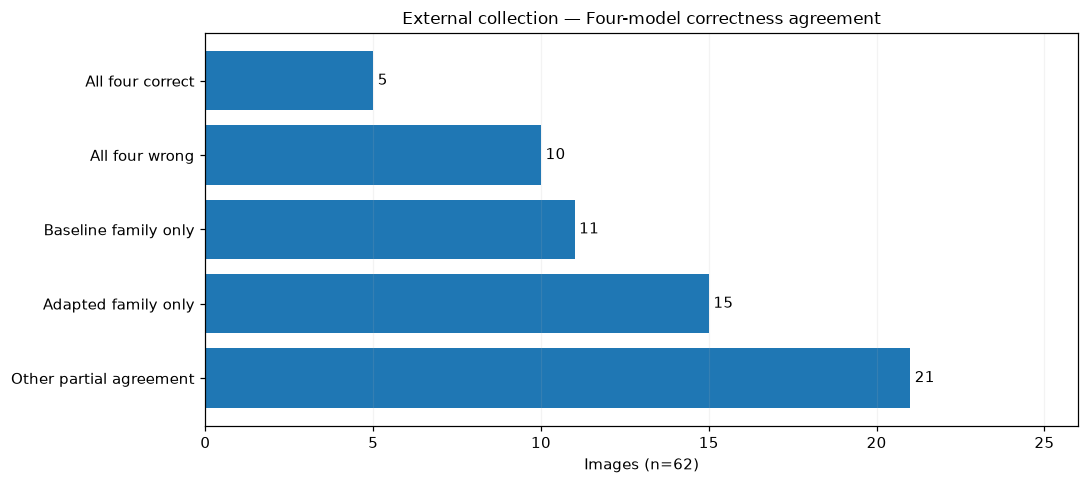

In [18]:
correct_columns = [f"{key}_correct" for key in MODEL_NAMES]
baseline_any = paired[["resnet_lab_correct", "vit_lab_correct"]].any(axis=1)
mixed_any = paired[["resnet_mixed_correct", "vit_mixed_correct"]].any(axis=1)
paired["agreement"] = np.select(
    [paired[correct_columns].all(axis=1), ~paired[correct_columns].any(axis=1),
     baseline_any & ~mixed_any, ~baseline_any & mixed_any],
    ["All four correct", "All four wrong", "Baseline family only", "Adapted family only"],
    default="Other partial agreement",
)
agreement_order = ["All four correct", "All four wrong", "Baseline family only", "Adapted family only", "Other partial agreement"]
agreement = paired.agreement.value_counts().reindex(agreement_order, fill_value=0).rename("images").to_frame()
assert agreement.images.sum() == 62
agreement.to_csv(OUTPUT_ROOT / "agreement_summary.csv")
paired.to_csv(OUTPUT_ROOT / "paired_predictions.csv", index=False)
display(agreement)
pair_rows = []
for phase in ("lab", "mixed"):
    cnn, vit = f"resnet_{phase}", f"vit_{phase}"
    paired[f"{phase}_label_disagreement"] = paired[f"{cnn}_predicted_label_id"] != paired[f"{vit}_predicted_label_id"]
    pair_rows.append({"phase": phase, "images": len(paired),
                      "label_disagreements": int(paired[f"{phase}_label_disagreement"].sum()),
                      "both_correct": int((paired[f"{cnn}_correct"] & paired[f"{vit}_correct"]).sum()),
                      "cnn_only_correct": int((paired[f"{cnn}_correct"] & ~paired[f"{vit}_correct"]).sum()),
                      "vit_only_correct": int((~paired[f"{cnn}_correct"] & paired[f"{vit}_correct"]).sum()),
                      "both_wrong": int((~paired[f"{cnn}_correct"] & ~paired[f"{vit}_correct"]).sum())})
pair_summary = pd.DataFrame(pair_rows)
pair_summary.to_csv(OUTPUT_ROOT / "cnn_vit_disagreement.csv", index=False)
paired.loc[paired.lab_label_disagreement | paired.mixed_label_disagreement].to_csv(
    OUTPUT_ROOT / "disagreement_images.csv", index=False,
)
display(pair_summary)
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(agreement.index, agreement.images)
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.set(title="External collection — Four-model correctness agreement", xlabel="Images (n=62)",
       xlim=(0, max(agreement.images)+5))
ax.grid(axis="x", alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "cross_model_agreement.png", dpi=160)
plt.show()
plt.close(fig)

In [19]:
shared = paired.loc[paired.agreement.eq("All four wrong")]
display(shared[["filename", "class_name", "image_type", "source_host", *prediction_columns]].rename(
    columns={f"{key}_predicted_label": label for key, label in SHORT_NAMES.items()}
))
display(Markdown(
    f"All four models agree on correctness for {int(agreement.loc['All four correct', 'images'])} successful "
    f"and {int(agreement.loc['All four wrong', 'images'])} unsuccessful images. Shared failures cover "
    f"{shared.class_name.nunique()} true classes. They are candidates for qualitative inspection, "
    "not evidence that the accepted labels are wrong. Repeated source pages and reviewed scene groups "
    "mean these images should not be treated as independent replications."
))

,filename,class_name,image_type,source_host,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
12,SC_0013.png,Healthy,cropped,self-collected,Late Blight,Late Blight,Late Blight,Late Blight
21,WEB_0006.jpg,Bacterial Spot,multi_leaf,apps.lucidcentral.org,Late Blight,Septoria Leaf Spot,Late Blight,Septoria Leaf Spot
27,WEB_0012.jpg,Early Blight,multi_leaf,ag.purdue.edu,Late Blight,Late Blight,Late Blight,Late Blight
31,WEB_0016.jpg,Early Blight,multi_leaf,ag.purdue.edu,Septoria Leaf Spot,Septoria Leaf Spot,Bacterial Spot,Bacterial Spot
43,WEB_0028.jpg,Septoria Leaf Spot,multi_leaf,ag.purdue.edu,Early Blight,Late Blight,Bacterial Spot,Bacterial Spot
44,WEB_0029.jpg,Septoria Leaf Spot,multi_leaf,ag.purdue.edu,Early Blight,Early Blight,Early Blight,Bacterial Spot
49,WEB_0034.jpg,Septoria Leaf Spot,single_leaf,u.osu.edu,Early Blight,Early Blight,Bacterial Spot,Early Blight
54,WEB_0039.png,Late Blight,cropped,gd.eppo.int,Early Blight,Early Blight,Septoria Leaf Spot,Healthy
58,WEB_0043.png,Bacterial Spot,cropped,gd.eppo.int,Late Blight,Septoria Leaf Spot,Late Blight,Septoria Leaf Spot
60,WEB_0045.png,Septoria Leaf Spot,cropped,ag.purdue.edu,Early Blight,Bacterial Spot,Bacterial Spot,Bacterial Spot


All four models agree on correctness for 5 successful and 10 unsuccessful images. Shared failures cover 5 true classes. They are candidates for qualitative inspection, not evidence that the accepted labels are wrong. Repeated source pages and reviewed scene groups mean these images should not be treated as independent replications.

## Image characteristics and shared failure cases

Recorded image types distinguish single-leaf, multi-leaf and cropped photographs.
The table also separates acquisition context. It reports correct counts with each
denominator; subgroup composition is retained in the saved CSV. Background clutter,
symptom visibility and visual ambiguity are discussed only for inspected examples,
not invented as quantitative attributes for the full dataset.

In [20]:
characteristics = []
for fields in (["image_type"], ["source_stratum", "image_type"], ["class_name", "image_type"]):
    for values, group in paired.groupby(fields, dropna=False, sort=True):
        values = values if isinstance(values, tuple) else (values,)
        subgroup = " | ".join(map(str, values))
        for key in MODEL_NAMES:
            characteristics.append({"grouping": " × ".join(fields), "subgroup": subgroup,
                                    "model_key": key, "images": len(group),
                                    "correct": int(group[f"{key}_correct"].sum()),
                                    "accuracy": float(group[f"{key}_correct"].mean()),
                                    "class_counts": json.dumps(group.class_name.value_counts().to_dict(), sort_keys=True)})
characteristics = pd.DataFrame(characteristics)
characteristics.to_csv(OUTPUT_ROOT / "image_characteristics.csv", index=False)
characteristics["correct_over_images"] = characteristics.correct.astype(str) + "/" + characteristics.images.astype(str)
for grouping in ("image_type", "source_stratum × image_type"):
    display(characteristics.loc[characteristics.grouping.eq(grouping)].pivot(
        index="subgroup", columns="model_key", values="correct_over_images"
    ).reindex(columns=MODEL_NAMES).rename(columns=SHORT_NAMES))

model_key,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
subgroup,,,,
cropped,3/18,9/18,9/18,10/18
multi_leaf,15/39,14/39,22/39,20/39
single_leaf,1/5,4/5,2/5,2/5


model_key,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
subgroup,,,,
self_collected_natural_context | cropped,0/8,4/8,5/8,7/8
self_collected_natural_context | multi_leaf,0/8,1/8,7/8,6/8
web_leaf_photo | cropped,3/9,5/9,4/9,3/9
web_leaf_photo | multi_leaf,15/31,13/31,15/31,14/31
web_leaf_photo | single_leaf,1/5,4/5,2/5,2/5
web_potted_experimental | cropped,0/1,0/1,0/1,0/1


In [21]:
show_gallery(["WEB_0006", "WEB_0028", "WEB_0034", "WEB_0043"],
             ["All four wrong; multi-leaf", "All four wrong; multi-leaf",
              "All four wrong; single-leaf", "All four wrong; potted experimental"],
             "shared_failure_examples.png", "Shared external failures — Selected photographic contexts (evaluation n=62)")
selected_metadata = pd.concat(selected_cases, ignore_index=True)
selected_metadata.to_csv(OUTPUT_ROOT / "selected_examples.csv", index=False)

,Filename,Ground truth,Image type,CNN Lab,ViT Lab,CNN Mixed,ViT Mixed
0,WEB_0006.jpg,Bacterial Spot,multi_leaf,Late Blight (0.68),Septoria Leaf Spot (0.94),Late Blight (0.35),Septoria Leaf Spot (0.89)
1,WEB_0028.jpg,Septoria Leaf Spot,multi_leaf,Early Blight (0.56),Late Blight (0.49),Bacterial Spot (0.68),Bacterial Spot (0.68)
2,WEB_0034.jpg,Septoria Leaf Spot,single_leaf,Early Blight (1.00),Early Blight (0.91),Bacterial Spot (0.72),Early Blight (0.93)
3,WEB_0043.png,Bacterial Spot,cropped,Late Blight (0.67),Septoria Leaf Spot (0.99),Late Blight (0.40),Septoria Leaf Spot (0.67)


WEB_0006 shows spotted and yellowing leaflets with dry vegetation behind them.
WEB_0028 shows a hand holding a spotted leaf against foliage, while WEB_0034 is a
closer view of several rounded dark marks with yellow surrounding areas. The latter
resembles some damaged regions in the Early Blight examples at a broad visual level;
this suggests a possible symptom-appearance overlap, not a verified diagnostic ambiguity.

WEB_0043 is the crop explicitly recorded as experimental/potted. Its visible foliage
and growing substrate differ from the close-up reference views, but one image cannot
establish a context-specific failure rate. Shared errors occur in both wider scenes
and close views. Cropping and multi-leaf composition are not controlled interventions,
and the retained groups differ in source and class mix.

## Discussion and conclusion

Class changes, acquisition-source results and shared errors summarize the fixed models.
The synthesis below distinguishes observed changes from unverified visual mechanisms.

The saved conclusion describes the scope at the time of this analysis. Notebook 14 subsequently reuses external v1 for exploratory crop sensitivity; the collection is therefore not an untouched holdout for the full project. Notebook 11 remains the canonical standard-transform evaluation. These error patterns motivate RQ3's closer examination of image framing in Notebooks 13–14, without establishing framing as their cause.

In [22]:
cnn = changes.loc[changes.architecture.eq("resnet")].set_index("class_name")
vit = changes.loc[changes.architecture.eq("vit")].set_index("class_name")
conclusion = (
    f"Mixed ResNet18 gains {int(cnn.net_correct.sum())} correct predictions overall: "
    f"Healthy contributes {int(cnn.loc['Healthy', 'net_correct']):+d}, "
    f"Late Blight {int(cnn.loc['Late Blight', 'net_correct']):+d}, "
    f"Bacterial Spot {int(cnn.loc['Bacterial Spot', 'net_correct']):+d} and "
    f"Septoria {int(cnn.loc['Septoria Leaf Spot', 'net_correct']):+d}, "
    f"offset by Early Blight {int(cnn.loc['Early Blight', 'net_correct']):+d}. "
    f"Mixed ViT gains {int(vit.net_correct.sum())} overall, with Healthy "
    f"{int(vit.loc['Healthy', 'net_correct']):+d} and Bacterial Spot "
    f"{int(vit.loc['Bacterial Spot', 'net_correct']):+d}, but Early Blight "
    f"{int(vit.loc['Early Blight', 'net_correct']):+d} and Septoria "
    f"{int(vit.loc['Septoria Leaf Spot', 'net_correct']):+d}; Late Blight has no net change.\n\n"
    f"The {int(agreement.loc['All four wrong', 'images'])} shared failures and the Early Blight losses "
    "show that higher aggregate accuracy does not resolve all disease-specific errors. "
    "The inspected photographs suggest heterogeneous symptoms and backgrounds, but predictions alone "
    "cannot establish which visual cues caused the changes. The CNN contrast also combines geometric "
    "initialization with mixed-domain adaptation.\n\n"
    "The principal improvement is Healthy recognition in the self-collected source category. "
    "Healthy/source confounding, uncertain image independence, small subgroups and annotation uncertainty "
    "prevent treating pooled accuracy as an unbiased estimate of real-world performance. "
    "Field Dev was used for model selection. This is neither general architectural superiority nor a controlled field-only versus mixed-domain comparison. No checkpoints were selected in this analysis. Notebook 14 subsequently reuses the collection for exploratory "
    "crop sensitivity, so it is not an untouched final holdout. Confirmation requires new, independently labeled and source-balanced data."
)
display(Markdown(conclusion))
(OUTPUT_ROOT / "findings.md").write_text("# External error analysis\n\n" + conclusion, encoding="utf-8")

Mixed ResNet18 gains 14 correct predictions overall: Healthy contributes +12, Late Blight +3, Bacterial Spot +4 and Septoria +5, offset by Early Blight -10. Mixed ViT gains 5 overall, with Healthy +8 and Bacterial Spot +3, but Early Blight -1 and Septoria -5; Late Blight has no net change.

The 10 shared failures and the Early Blight losses show that higher aggregate accuracy does not resolve all disease-specific errors. The inspected photographs suggest heterogeneous symptoms and backgrounds, but predictions alone cannot establish which visual cues caused the changes. The CNN contrast also combines geometric initialization with mixed-domain adaptation.

The principal improvement is Healthy recognition in the self-collected source category. Healthy/source confounding, uncertain image independence, small subgroups and annotation uncertainty prevent treating pooled accuracy as an unbiased estimate of real-world performance. Field Dev was used for model selection. This is neither general architectural superiority nor a controlled field-only versus mixed-domain comparison. The external collection remains outside subsequent checkpoint selection or tuning. Confirmation requires new, independently labeled and source-balanced data.

1270

In [23]:
analysis_record = {
    "evaluation_run": os.path.relpath(EVALUATION_RUN, PROJECT_ROOT), "evaluation_run_id": protocol["run_id"],
    "evaluation_protocol_sha256": selected_run["protocol_sha256"],
    "model_summary_sha256": selected_run["summary_sha256"],
    "manifest_sha256": sha256_file(manifest_path), "prediction_files_sha256": input_hashes,
    "checkpoint_sha256": {key: value["checkpoint_sha256"] for key,value in protocol["checkpoints_and_preprocessing"].items()},
    "class_mapping": LABEL_MAP, "images": len(paired),
    "selected_example_ids": selected_metadata.image_id.tolist(),
    "inference_performed": False, "training_or_tuning_performed": False,
    "qualitative_scope": "Author-inspected selected photographs; descriptive observations, not expert diagnosis or causal attribution",
    "limitations": ["source/class confounding", "image and source dependence", "small subgroups",
                    "annotation uncertainty", "illustrative case selection", "uncalibrated softmax confidence"],
}
(OUTPUT_ROOT / "analysis_protocol.json").write_text(json.dumps(analysis_record, indent=2), encoding="utf-8")
for filename, digest in input_hashes.items():
    assert sha256_file(EVALUATION_RUN / filename) == digest
assert sha256_file(manifest_path) == protocol["manifest_sha256"]
assert sha256_file(protocol_path) == selected_run["protocol_sha256"]
assert sha256_file(EVALUATION_RUN / "model_summary.csv") == selected_run["summary_sha256"]
print("Saved analysis:", OUTPUT_ROOT.relative_to(PROJECT_ROOT))

Saved analysis: outputs/external_error_analysis/tomato_field_eval_v1/20261125_163458_b8ce4dcb
